# 02 EDA: delays by traffic type and weather

**Owner:** LK · **Date:** 2026-11-09 · **Purpose:** descriptive EDA for the concept presentation
(slide "Data" and the preliminary chart), no tests and no controls yet (tests: issue #20).

**Input:** table `analysis_base` (release `data-v1`, one row = one train arrival at a stop in canton ZH),
`weather_hourly`. **Output:** figures and the numbers for the slides.

Definitions are taken from `docs/research-design.md` and not changed here:
delayed = arrival delay >= 3 min; regional = S; long-distance = IC, IR, RE, EC, ICE, TGV, RJX, RJ, NJ;
precipitation = rain or snow in the last full hour before the scheduled arrival.

Sources: opentransportdata.swiss (Ist-Daten, service points), Source: MeteoSwiss.
Note: 28.-31.01.2025 are missing (450 of 454 days), see `docs/data-releases.md`.

## 0. Setup
Imports and plot style. Colours are fixed so that regional and long-distance look the same in every chart.

In [1]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.db import query, list_tables

sns.set_theme(style="whitegrid")
# One colour per traffic type, used in every chart (slide rule: consistent colours)
COLORS = {"regional": "#1f77b4", "long_distance": "#d62728"}
SOURCE = "Source: opentransportdata.swiss, MeteoSwiss; own calculation"
print(list_tables())

## 1. Size and structure of the data
SQL `GROUP BY` counts rows, days and stops per winter and traffic type (aggregation in SQL, not pandas).

In [2]:
size = query("""
    SELECT winter, traffic_type,
           COUNT(*)                 AS arrivals,
           COUNT(DISTINCT service_date) AS days,
           COUNT(DISTINCT bpuic)    AS stops
    FROM analysis_base
    GROUP BY winter, traffic_type
    ORDER BY winter, traffic_type
""")
size

Column names, types and a first look at missing values (for the slide "Data structure"). A small sample is enough for the types, NULL counts are done in SQL on the full table.

In [3]:
sample = query("SELECT * FROM analysis_base LIMIT 1000")
print(sample.dtypes.to_string())

In [4]:
# Share of NULLs in the columns that can be missing (SUM(CASE ...) works on SQLite and PostgreSQL)
nulls = query("""
    SELECT traffic_type,
           COUNT(*) AS n,
           ROUND(100.0 * SUM(CASE WHEN entry_delay_min IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_entry_delay_null,
           ROUND(100.0 * SUM(CASE WHEN prev_dep_delay_min IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_prev_dep_null,
           ROUND(100.0 * SUM(CASE WHEN precip_mm IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_precip_null
    FROM analysis_base
    GROUP BY traffic_type
""")
nulls

## 2. Distribution of the arrival delay
SQL counts arrivals per full minute (rounded), clipped to -5 ... +20 min so that the long tail does not hide the shape. The 3-minute threshold is marked.

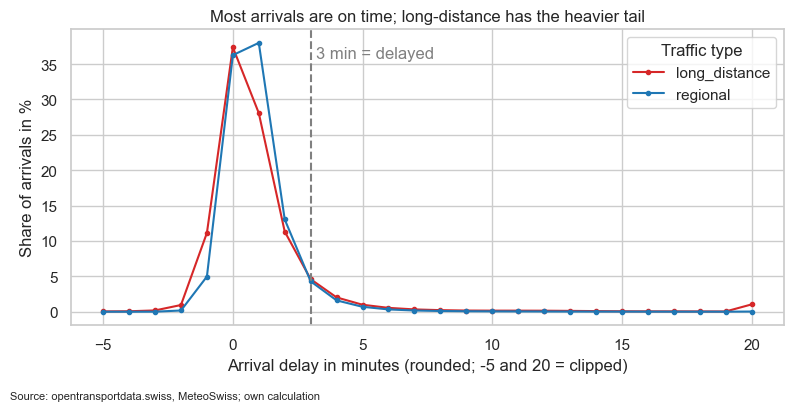

In [5]:
hist = query("""
    SELECT traffic_type,
           CASE WHEN ROUND(arr_delay_min) < -5 THEN -5
                WHEN ROUND(arr_delay_min) > 20 THEN 20
                ELSE CAST(ROUND(arr_delay_min) AS INTEGER) END AS delay_bin,
           COUNT(*) AS n
    FROM analysis_base
    GROUP BY traffic_type, delay_bin
""")
# Share within each traffic type, so that the very different group sizes are comparable
hist["share"] = hist["n"] / hist.groupby("traffic_type")["n"].transform("sum")

fig, ax = plt.subplots(figsize=(8, 4))
for t, g in hist.groupby("traffic_type"):
    ax.plot(g["delay_bin"], 100 * g["share"], marker="o", ms=3, label=t, color=COLORS[t])
ax.axvline(3, color="grey", ls="--"); ax.text(3.2, ax.get_ylim()[1] * 0.9, "3 min = delayed", color="grey")
ax.set_title("Most arrivals are on time; long-distance has the heavier tail")
ax.set_xlabel("Arrival delay in minutes (rounded; -5 and 20 = clipped)"); ax.set_ylabel("Share of arrivals in %")
ax.legend(title="Traffic type"); fig.text(0.01, -0.02, SOURCE, fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
# Summary numbers per traffic type (min/max and average in SQL; quantiles are not portable SQL)
query("""
    SELECT traffic_type, COUNT(*) AS n,
           ROUND(AVG(arr_delay_min), 2) AS mean_delay_min,
           MIN(arr_delay_min) AS min_delay_min, MAX(arr_delay_min) AS max_delay_min,
           ROUND(100.0 * AVG(delayed), 2) AS pct_delayed
    FROM analysis_base GROUP BY traffic_type
""")

## 3. Delay rate by traffic type and weather
Core descriptive table: share of arrivals with delay >= 3 min per traffic type and `precip_cat`.
The effect (precipitation minus dry, in percentage points) is the primary measure, the risk ratio the robustness check (decision of 2026-11-03).
**Preliminary:** no controls (hour, weekday, holiday ...) and no test yet, so not a causal effect.

In [7]:
rates = query("""
    SELECT traffic_type, precip_cat,
           COUNT(*)             AS n,
           SUM(delayed)         AS n_delayed,
           100.0 * AVG(delayed) AS pct_delayed
    FROM analysis_base
    GROUP BY traffic_type, precip_cat
    ORDER BY traffic_type, precip_cat
""")
rates

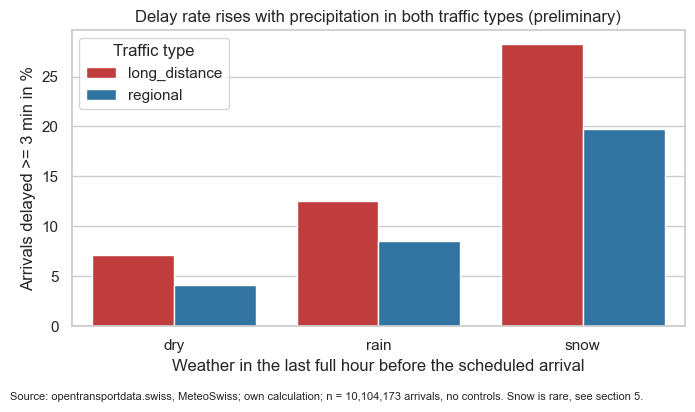

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ["dry", "rain", "snow"]
sns.barplot(data=rates, x="precip_cat", y="pct_delayed", hue="traffic_type", order=order,
            palette=COLORS, ax=ax)
ax.set_title("Delay rate rises with precipitation in both traffic types (preliminary)")
ax.set_xlabel("Weather in the last full hour before the scheduled arrival")
ax.set_ylabel("Arrivals delayed >= 3 min in %"); ax.legend(title="Traffic type")
n_total = int(rates["n"].sum())
fig.text(0.01, -0.02, f"{SOURCE}; n = {n_total:,} arrivals, no controls. Snow is rare, see section 5.", fontsize=8)
plt.tight_layout(); plt.show()

In [9]:
# Effect = rate with precipitation (rain + snow) minus rate when dry, per traffic type.
# precip_any is the 0/1 flag used for the main comparison; computed in SQL.
pa = query("""
    SELECT traffic_type, precip_any, COUNT(*) AS n, 100.0 * AVG(delayed) AS pct_delayed
    FROM analysis_base GROUP BY traffic_type, precip_any
""")
wide = pa.pivot(index="traffic_type", columns="precip_any", values="pct_delayed")
effect = pd.DataFrame({
    "dry_pct": wide[0], "precip_pct": wide[1],
    "effect_pp": wide[1] - wide[0],          # primary: absolute difference in percentage points
    "risk_ratio": wide[1] / wide[0],         # robustness check: relative difference
}).round(2)
effect

**Reading:** in percentage points the effect is larger for long-distance traffic, relative to the baseline it is larger for regional traffic.
Which of the two answers "stronger" was fixed before looking at the data (absolute = primary). Controls and the z-test come in issue #20.

## 4. Delay rate by hour, split by weather
Hour of day is the main confounder (rush hour), so we look at it before any interpretation.

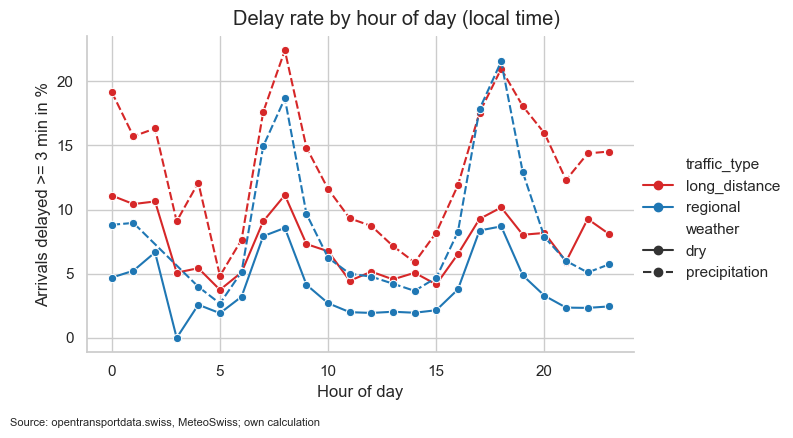

In [10]:
by_hour = query("""
    SELECT hour, traffic_type, precip_any,
           COUNT(*) AS n, 100.0 * AVG(delayed) AS pct_delayed
    FROM analysis_base
    GROUP BY hour, traffic_type, precip_any
    ORDER BY hour
""")
by_hour["weather"] = by_hour["precip_any"].map({0: "dry", 1: "precipitation"})
g = sns.relplot(data=by_hour, x="hour", y="pct_delayed", hue="traffic_type", style="weather",
                kind="line", palette=COLORS, height=4, aspect=1.6, marker="o")
g.figure.suptitle("Delay rate by hour of day (local time)", y=1.02)
g.set_axis_labels("Hour of day", "Arrivals delayed >= 3 min in %")
g.figure.text(0.01, -0.02, SOURCE, fontsize=8); plt.show()

## 5. How much precipitation is there? Hours per winter
Share of weather hours (with train traffic at a stop) per category and winter. A sub-select with `SELECT DISTINCT` counts each station-hour once,
not once per train, so the shares describe the weather and not the timetable.

In [11]:
hours = query("""
    SELECT winter, precip_cat, COUNT(*) AS station_hours
    FROM (SELECT DISTINCT winter, precip_station, weather_hour_utc, precip_cat FROM analysis_base) AS h
    GROUP BY winter, precip_cat
""")
hours["share_pct"] = 100 * hours["station_hours"] / hours.groupby("winter")["station_hours"].transform("sum")
hours.pivot(index="winter", columns="precip_cat", values="share_pct").round(1)

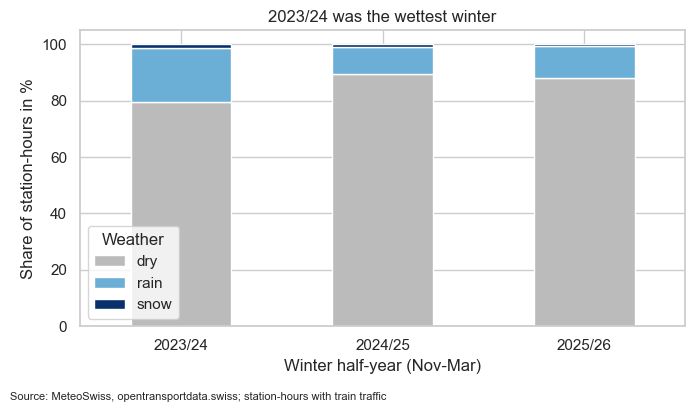

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
p = hours.pivot(index="winter", columns="precip_cat", values="share_pct")[["dry", "rain", "snow"]]
p.plot(kind="bar", stacked=True, ax=ax, color=["#bbbbbb", "#6baed6", "#08306b"])
ax.set_title("2023/24 was the wettest winter"); ax.set_xlabel("Winter half-year (Nov-Mar)")
ax.set_ylabel("Share of station-hours in %"); ax.legend(title="Weather"); plt.xticks(rotation=0)
fig.text(0.01, -0.02, "Source: MeteoSwiss, opentransportdata.swiss; station-hours with train traffic", fontsize=8)
plt.tight_layout(); plt.show()

In [13]:
# Number of arrivals under snow: how thin is the snow sub-analysis?
query("""SELECT traffic_type, precip_cat, COUNT(*) AS arrivals
          FROM analysis_base WHERE precip_cat = 'snow' GROUP BY traffic_type, precip_cat""")

## Findings (for the slides)
Run of 2026-11-09 on release `data-v1` (10,104,173 arrivals, 450 of 454 days; descriptive, no controls, no tests):

- **Size:** regional 9.51 M arrivals at 156-157 stops per winter, long-distance 0.59 M at 25-31 stops. Long-distance is only 5.8 % of the data.
- **Delay rate overall:** regional 4.8 %, long-distance 8.0 % (delay >= 3 min).
- **Precipitation vs. dry:** regional 4.1 % -> 9.2 % (+5.1 pp, risk ratio 2.24); long-distance 7.1 % -> 13.4 % (+6.3 pp, risk ratio 1.88).
  The absolute effect is larger for long-distance traffic, the relative one for regional traffic.
  (Rain + snow combined; the 03.11. decision fixed the absolute effect as primary before the data was seen.)
- **Snow:** regional 19.8 %, long-distance 28.2 % delayed, but only 79,835 and 4,729 arrivals: wide confidence intervals later.
- **Weather share:** dry 79.7 % / 89.6 % / 88.0 % of station-hours in 2023/24 / 2024/25 / 2025/26, so 2023/24 was the wettest winter.
- **Confounding is visible:** the delay rate peaks at 07-09 h and 17-19 h in both groups, also when dry. Hour, weekday and holiday must be controlled in #20.
- **Missing values:** `entry_delay_min` is NULL for 60.3 % of regional and 18.9 % of long-distance arrivals (as documented), `precip_mm` has no NULLs.

## Open questions
- Absolute vs. relative effect point in different directions: how do we word this on the slide "Expected results"?
- Hour of day differs between traffic types: needs controls before any interpretation (issue #20).

### Jupyter notebook --footer info--

In [14]:
import os, platform
from platform import python_version
from datetime import datetime
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')